# Capítulo 5 · Árboles: clasificar y predecir un número

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/lectures/chapter_05/05_arboles_clasificacion_y_regresion.ipynb)

**Aprendizaje supervisado · Uso del árbol de decisión**

Un árbol de decisión sirve para las dos tareas. La pregunta que hace es la misma (`¿esta variable es menor que este umbral?`). Cambia lo que contesta la hoja:

- **Clasificación:** la clase más frecuente de los ejemplos que cayeron ahí.
- **Regresión:** el promedio del número que queremos predecir.

Sin límites de tamaño, el árbol crece hasta que las hojas son puras o ya no puede dividirlas. Puede memorizar el entrenamiento. `max_depth` limita su crecimiento y `ccp_alpha` permite podarlo después.

### 📚 Índice
1. Iris: un vistazo y clasificar
2. Hiperparámetros: hasta dónde dejar crecer el árbol
3. Dejar crecer y después podar
4. Autos: un vistazo y predecir millas por galón
5. Chuleta resumen


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

sns.set_theme(style="whitegrid")
palette = sns.color_palette("deep")

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = raiz / "data"


---
## 1. Iris: un vistazo y clasificar

150 flores, 4 medidas en centímetros y 3 especies. `target` vale 0, 1 o 2: setosa, versicolor y virginica.


In [2]:
iris = pd.read_csv(DATA_DIR / "iris.csv")
especies = ["setosa", "versicolor", "virginica"]
iris.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Cómo se ve

Tres especies con 50 flores cada una. En el pétalo, la setosa queda aparte; versicolor y virginica se acercan. El largo y el ancho del pétalo van casi juntos.


In [3]:
iris["target"].map(dict(enumerate(especies))).value_counts().rename("flores")


target
setosa        50
versicolor    50
virginica     50
Name: flores, dtype: int64

In [4]:
iris.drop(columns="target").describe()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


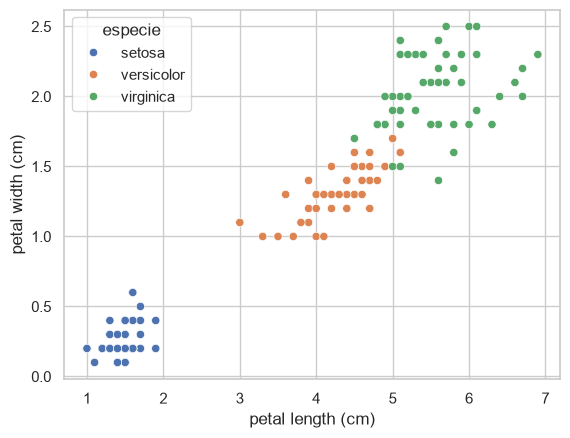

In [5]:
iris_plot = iris.assign(especie=iris["target"].map(dict(enumerate(especies))))
sns.scatterplot(
    data=iris_plot, x="petal length (cm)", y="petal width (cm)",
    hue="especie", palette=palette[:3]
)
plt.show()


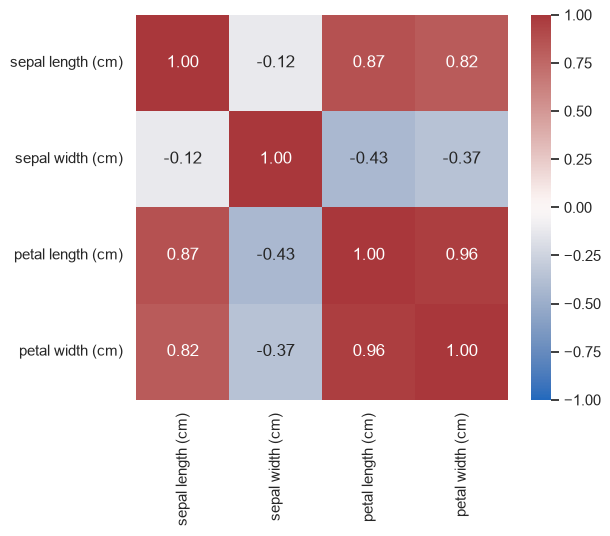

In [6]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    iris.drop(columns="target").corr(), annot=True, fmt=".2f",
    cmap="vlag", center=0, vmin=-1, vmax=1
)
plt.show()


`stratify=y` mantiene la proporción de especies en train y en test. En regresión no se usa de esta forma.

Reservamos el 20 % para la evaluación final. La profundidad y la poda se compararán con validación cruzada dentro del 80 % de entrenamiento; el test no interviene en la elección.


In [7]:
X = iris.drop(columns="target")
y = iris["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

arbol = DecisionTreeClassifier(max_depth=None, ccp_alpha=0.0, random_state=42)
arbol.fit(X_train, y_train)

print(f"Accuracy en train: {arbol.score(X_train, y_train):.2f}")
print(f"Profundidad alcanzada: {arbol.get_depth()}")
print(f"Hojas: {arbol.get_n_leaves()}")


Accuracy en train: 1.00
Profundidad alcanzada: 5
Hojas: 8


El 1.00 en train indica que este árbol acierta todas las flores con las que se entrenó; por sí solo no demuestra que generalice bien. `max_depth=None` deja que crezca hasta donde permiten los datos y las demás reglas de parada: la profundidad no es infinita.

Abajo mostramos solo los primeros niveles. El `max_depth=2` de **`plot_tree` recorta el dibujo**, no el modelo entrenado. Más adelante veremos el árbol completo antes y después de podarlo.


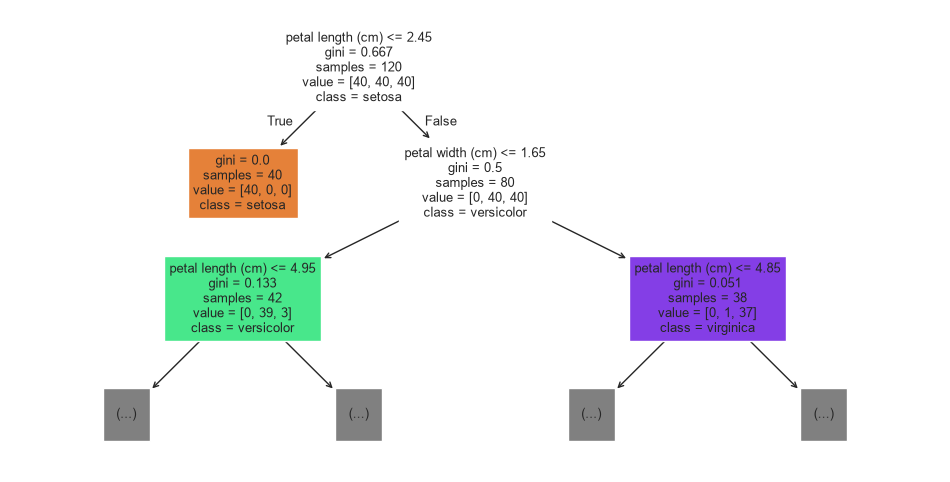

In [8]:
plt.figure(figsize=(12, 6))
plot_tree(
    arbol, max_depth=2, filled=True, feature_names=X.columns, class_names=especies,
    fontsize=9
)
plt.show()


---
## 2. Hiperparámetros: hasta dónde dejar crecer el árbol

Los **hiperparámetros** se fijan antes de entrenar. El árbol aprende las variables y los umbrales de sus preguntas; tú decides las reglas que controlan ese aprendizaje.

| Hiperparámetro | Qué controla | Ejemplo |
|---|---|---|
| `max_depth` | Profundidad máxima | `3`: hasta tres decisiones por camino |
| `min_samples_split` | Ejemplos necesarios en un nodo para intentar dividirlo | `10` |
| `min_samples_leaf` | Ejemplos mínimos en cada hoja | `5`: evita hojas con una sola flor |
| `criterion` | Medida de calidad de las divisiones | En clasificación: `"gini"`, `"entropy"`, `"log_loss"` |
| `max_leaf_nodes` | Número máximo de hojas | `10` |
| `max_features` | Variables consideradas al buscar una división | `None`: todas |
| `ccp_alpha` | Intensidad de la poda por costo-complejidad | `0.0`: sin poda posterior |
| `class_weight` | Peso de cada clase | `"balanced"`: compensa frecuencias desiguales |

Otras opciones son `splitter` (estrategia de división), `min_impurity_decrease` (mejora mínima para dividir), `min_weight_fraction_leaf` (peso mínimo por hoja) y `monotonic_cst` (restricciones de monotonía, con limitaciones según el problema). `random_state=42` fija la aleatoriedad para reproducir resultados; no lo buscamos como hiperparámetro para mejorar la puntuación.

Referencia: [parámetros de DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).

Empieza con `max_depth` y `min_samples_leaf`: menor profundidad o más ejemplos por hoja producen árboles más simples. Restringir demasiado puede causar **subajuste**.

### Limitar el crecimiento: prepoda

Comparamos profundidades con las mismas cinco particiones estratificadas. La columna de train evalúa el ajuste sobre todo el entrenamiento; la de validación promedia predicciones sobre flores que cada modelo no usó para entrenarse.


In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

filas = []
for profundidad in [1, 2, 3, None]:
    modelo = DecisionTreeClassifier(max_depth=profundidad, random_state=42)
    modelo.fit(X_train, y_train)
    scores = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="accuracy")
    filas.append({
        "max_depth": "sin límite" if profundidad is None else profundidad,
        "accuracy_train": modelo.score(X_train, y_train),
        "accuracy_validacion": scores.mean(),
    })

pd.DataFrame(filas).round(3)


,max_depth,accuracy_train,accuracy_validacion
0,1,0.667,0.667
1,2,0.967,0.942
2,3,0.983,0.958
3,sin límite,1.000,0.950


---
## 3. Dejar crecer y después podar

**Prepoda** limita el crecimiento desde el inicio. La **poda por costo-complejidad** parte de un árbol desarrollado y elimina ramas cuyo aporte no compensa su complejidad. `ccp_alpha` controla esa penalización: al aumentarlo, quedan menos hojas; con un valor suficientemente grande, solo queda la raíz.

Mantendremos `max_depth=None`, los mismos datos y la misma semilla. En scikit-learn ajustamos una versión del árbol para cada alpha: `fit` construye el árbol y aplica la poda; cambiar el parámetro de un árbol ya entrenado no lo poda automáticamente.

### Elegir alpha con validación cruzada

Probamos una cuadrícula fija de 0 a 0.4, incluyendo el árbol sin poda. En este ejemplo el extremo permite observar el subajuste; el rango adecuado depende del problema. `return_train_score=True` guarda también la accuracy de entrenamiento de cada partición. Aquí las dos curvas serán **medias sobre las mismas cinco particiones**.

Referencia: [ejemplo oficial de poda por costo-complejidad](https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html).


In [10]:
alphas = np.linspace(0.0, 0.4, 81)
busqueda_poda = GridSearchCV(
    DecisionTreeClassifier(max_depth=None, random_state=42),
    param_grid={"ccp_alpha": alphas},
    scoring="accuracy",
    cv=cv,
    return_train_score=True,
    refit=False,
    error_score="raise",
)
busqueda_poda.fit(X_train, y_train)

resultados_poda = pd.DataFrame(busqueda_poda.cv_results_)
curva_poda = pd.DataFrame({
    "alpha": resultados_poda["param_ccp_alpha"].astype(float),
    "train": resultados_poda["mean_train_score"],
    "validacion": resultados_poda["mean_test_score"],
    "std_validacion": resultados_poda["std_test_score"],
})

# Si empatan en validación, elegimos el alpha mayor: favorece un árbol más simple.
mejor_fila = curva_poda.sort_values(
    ["validacion", "alpha"], ascending=[False, False]
).iloc[0]
mejor_alpha = float(mejor_fila["alpha"])
print(f"Alpha elegido: {mejor_alpha:.3f}")
print(f"Accuracy de validación: {mejor_fila['validacion']:.3f}")
curva_poda.head()


Alpha elegido: 0.020
Accuracy de validación: 0.967


,alpha,train,validacion,std_validacion
0,0.000,1.000000,0.950000,0.016667
1,0.005,1.000000,0.950000,0.016667
2,0.010,0.995833,0.958333,0.026352
3,0.015,0.983333,0.966667,0.031180
4,0.020,0.979167,0.966667,0.031180


Aunque el resultado de `GridSearchCV` se llama `mean_test_score`, aquí corresponde a la **validación interna**, no a `X_test`.

### Accuracy frente a alpha

Las líneas escalonadas conectan los valores probados. La vista ampliada permite distinguir la poda suave; la vista completa muestra qué ocurre al podar demasiado. Usamos **accuracy (proporción de aciertos)**, que es distinta de la métrica `precision`.


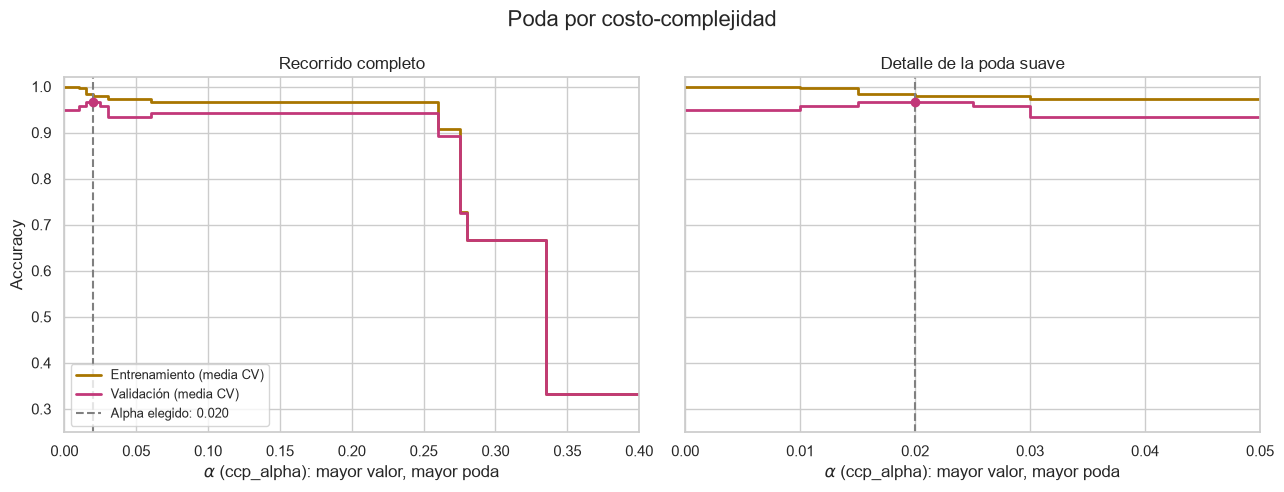

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax in axes:
    ax.step(curva_poda["alpha"], curva_poda["train"], where="post",
            label="Entrenamiento (media CV)", color="#a87500", linewidth=2)
    ax.step(curva_poda["alpha"], curva_poda["validacion"], where="post",
            label="Validación (media CV)", color="#c23879", linewidth=2)
    ax.axvline(mejor_alpha, color="gray", linestyle="--", label=f"Alpha elegido: {mejor_alpha:.3f}")
    ax.scatter([mejor_alpha], [mejor_fila["validacion"]], color="#c23879", zorder=3)
    ax.set_xlabel(r"$\alpha$ (ccp_alpha): mayor valor, mayor poda")
    ax.set_ylim(0.25, 1.02)
axes[0].set_xlim(0, alphas.max())
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Recorrido completo")
axes[1].set_xlim(0, 0.05)
axes[1].set_title("Detalle de la poda suave")
axes[0].legend(loc="lower left", fontsize=9)
fig.suptitle("Poda por costo-complejidad", fontsize=16)
plt.tight_layout()
plt.show()


La validación puede mejorar, empatar o empeorar al podar: no hay una forma de curva garantizada. En Iris hay pocas ramas que eliminar, por eso aparecen pocos escalones. Un alpha grande termina dejando un modelo demasiado simple y reduce ambas puntuaciones.

### El árbol completo y su versión podada

Reentrenamos con el alpha elegido sobre las mismas flores que usó `arbol`. Ahora dibujamos **todos los niveles** de ambos árboles; compara las hojas y la profundidad. Si otro conjunto de datos favorece `alpha=0`, lo correcto es conservar el árbol sin poda.


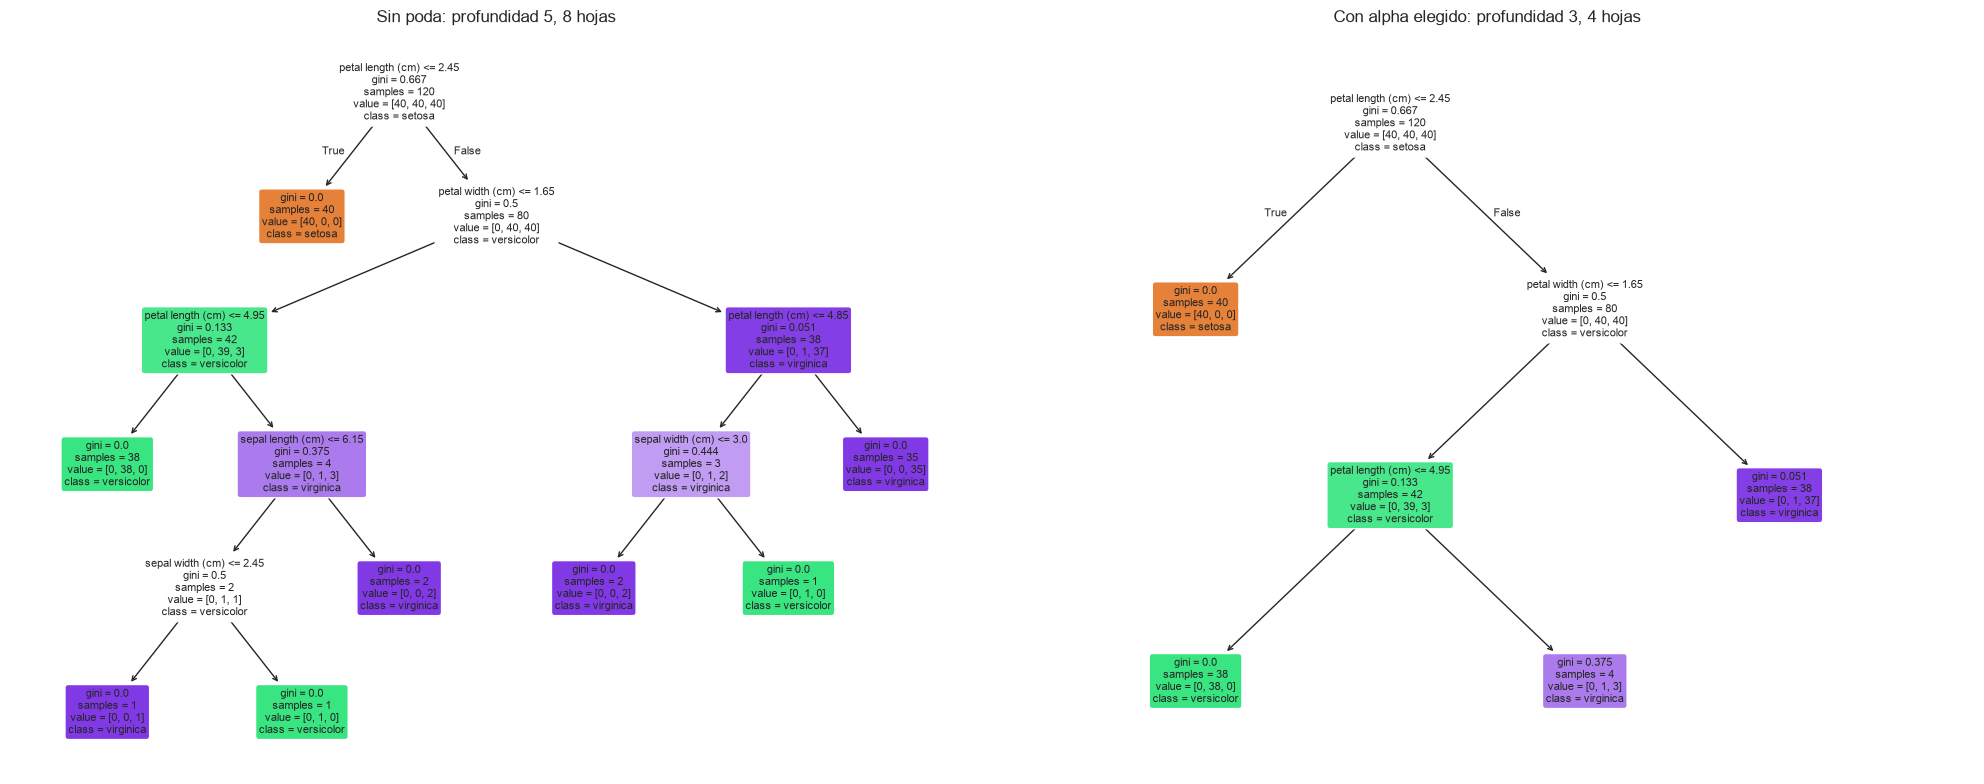

In [12]:
arbol_podado = DecisionTreeClassifier(
    max_depth=None, ccp_alpha=mejor_alpha, random_state=42
)
arbol_podado.fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, nombre, modelo in zip(
    axes, ["Sin poda", "Con alpha elegido"], [arbol, arbol_podado]
):
    plot_tree(modelo, filled=True, feature_names=X.columns, class_names=especies,
              rounded=True, fontsize=8, ax=ax)
    ax.set_title(
        f"{nombre}: profundidad {modelo.get_depth()}, {modelo.get_n_leaves()} hojas"
    )
plt.tight_layout()
plt.show()


### Evaluación final

Con alpha ya elegido, consultamos test una sola vez para comparar el árbol original y el seleccionado. La mejora en validación no garantiza una mejora en test, especialmente con solo 30 flores. No volvemos a ajustar alpha mirando esta tabla.


In [13]:
comparacion_poda = []
for nombre, modelo in [("Sin poda", arbol), ("Con alpha elegido", arbol_podado)]:
    comparacion_poda.append({
        "modelo": nombre,
        "alpha": modelo.ccp_alpha,
        "profundidad": modelo.get_depth(),
        "hojas": modelo.get_n_leaves(),
        "accuracy_train": modelo.score(X_train, y_train),
        "accuracy_test": modelo.score(X_test, y_test),
    })

pd.DataFrame(comparacion_poda).round(3)


,modelo,alpha,profundidad,hojas,accuracy_train,accuracy_test
0,Sin poda,0.00,5,8,1.000,0.933
1,Con alpha elegido,0.02,3,4,0.983,0.967


---
## 4. Autos: un vistazo y predecir las millas por galón

El regresor se usa igual: `fit` y `predict`. En la hoja no hay una clase, hay el **promedio** de `mpg` de los autos que cayeron ahí. Por eso la predicción es una escalera, no una recta.


### Cómo se ve

398 autos. `horsepower` es la única columna con huecos: 6 filas. El peso y las millas por galón se mueven juntos, al revés: a más peso, menos `mpg`.


In [14]:
autos = pd.read_csv(DATA_DIR / "mpg.csv")
autos.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [15]:
autos.isna().sum().rename("nulos")


mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
Name: nulos, dtype: int64

In [16]:
autos.describe()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


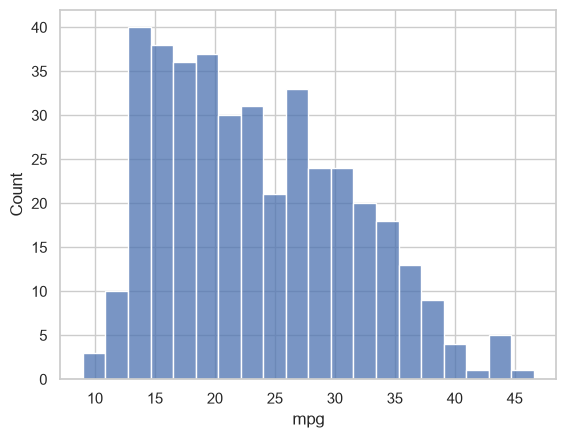

In [17]:
sns.histplot(data=autos, x="mpg", bins=20, color=palette[0])
plt.show()


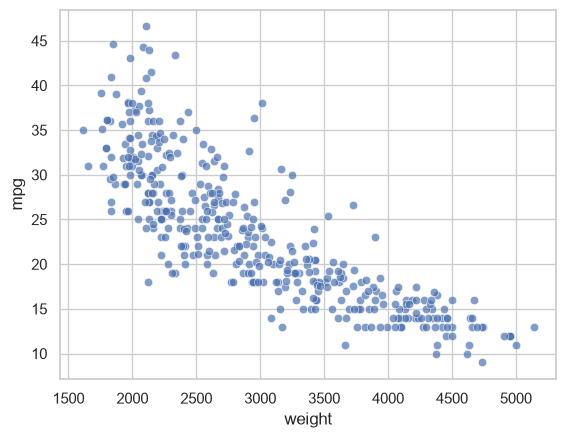

In [18]:
sns.scatterplot(data=autos, x="weight", y="mpg", color=palette[0], alpha=0.7)
plt.show()


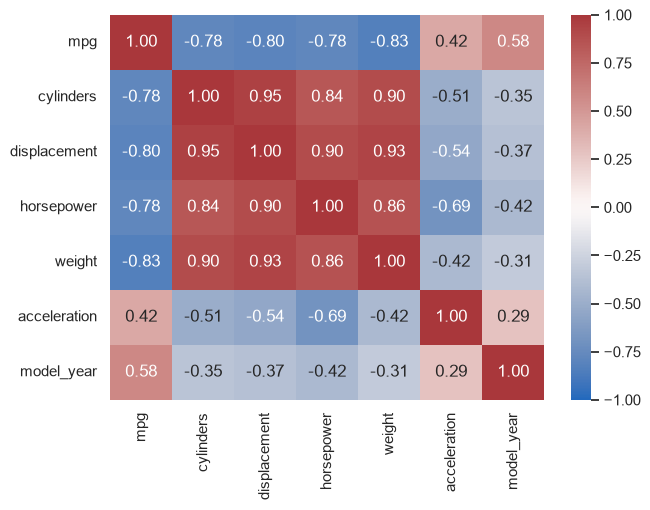

In [19]:
plt.figure(figsize=(7, 5))
sns.heatmap(autos.corr(numeric_only=True), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.show()


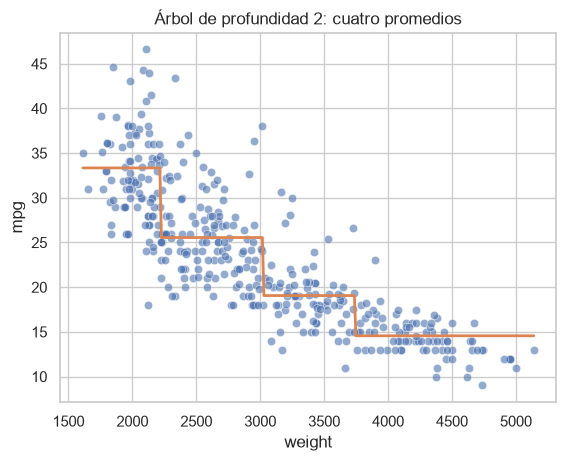

In [20]:
autos = autos.dropna()
X_peso = autos[["weight"]]
y_mpg = autos["mpg"]
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_peso, y_mpg, test_size=0.2, random_state=42
)

regresor = DecisionTreeRegressor(max_depth=2, random_state=42)
regresor.fit(X_train_p, y_train_p)

pesos = np.linspace(autos["weight"].min(), autos["weight"].max(), 300)
prediccion = regresor.predict(pd.DataFrame({"weight": pesos}))

sns.scatterplot(data=autos, x="weight", y="mpg", color=palette[0], alpha=0.6)
plt.plot(pesos, prediccion, color=palette[1], linewidth=2)
plt.title("Árbol de profundidad 2: cuatro promedios")
plt.show()


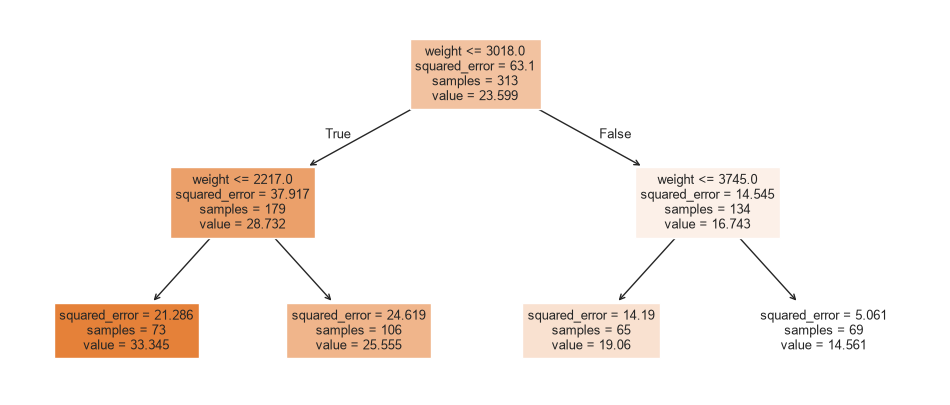

In [21]:
plt.figure(figsize=(12, 5))
plot_tree(regresor, filled=True, feature_names=["weight"], fontsize=9)
plt.show()


Con más variables el uso no cambia. Aquí entran peso, potencia y año. Sin límite, el $R^2$ de train llega casi a 1 y se separa del de test: el árbol ajusta autos sueltos del entrenamiento. Con profundidad 4 el de test queda parecido y el de train ya no está pegado a 1.


In [22]:
columnas = ["weight", "horsepower", "model_year"]
X_auto = autos[columnas]
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_auto, y_mpg, test_size=0.2, random_state=42
)

filas = []
for profundidad in [2, 4, None]:
    modelo = DecisionTreeRegressor(max_depth=profundidad, random_state=42)
    modelo.fit(X_train_a, y_train_a)
    pred_test = modelo.predict(X_test_a)
    filas.append({
        "max_depth": "sin límite" if profundidad is None else profundidad,
        "R2_train": modelo.score(X_train_a, y_train_a),
        "R2_test": modelo.score(X_test_a, y_test_a),
        "RMSE_test": root_mean_squared_error(y_test_a, pred_test),
    })

pd.DataFrame(filas).round(3)


,max_depth,R2_train,R2_test,RMSE_test
0,2,0.741,0.594,4.553
1,4,0.888,0.791,3.267
2,sin límite,0.998,0.806,3.146


---
## 5. 📋 Chuleta resumen

| Tarea | Código |
|---|---|
| Clasificar | `DecisionTreeClassifier(random_state=42)` |
| Predecir un número | `DecisionTreeRegressor(random_state=42)` |
| Entrenar y predecir | `.fit(X_train, y_train)`, `.predict(X_test)` |
| Accuracy o $R^2$ | `.score(X_test, y_test)` |
| Frenar el árbol | `max_depth=3` o `min_samples_leaf=5` |
| Podar después de crecer | `DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)` y volver a ajustar |
| Medir su tamaño | `modelo.get_depth()`, `modelo.get_n_leaves()` |
| Dibujarlo | `plot_tree(modelo, feature_names=X.columns, max_depth=2)` |
| Train y test, clasificación | `train_test_split(..., stratify=y, random_state=42)` |
| Train y test, regresión | `train_test_split(..., random_state=42)` sin `stratify` |

> 💡 A un árbol no le importa que las variables estén en escalas distintas: solo compara cada una con un umbral. Estandarizar no le cambia el resultado.
